# Coverage and missingness

In [1]:
import numpy as np
import polars as pl
import matplotlib.pyplot as plt
from eda_data import *

In [2]:
chars = char_names()
lf = chars_lazy()
lf.select(rows=pl.len(), firms=pl.col("permno").n_unique(), months=pl.col("DATE").n_unique(),
          first=pl.col("DATE").min(), last=pl.col("DATE").max()).collect()

rows,firms,months,first,last
u32,u32,u32,i64,i64
2383384,22523,346,19900228,20181130


## Firm-months per month at each filter step

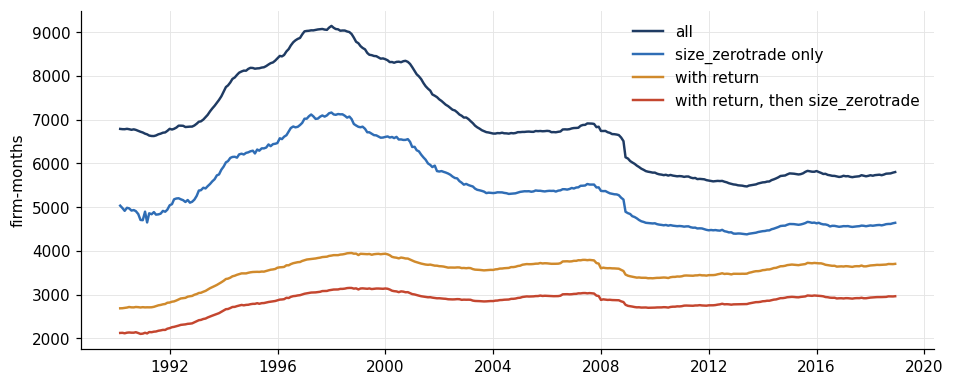

In [3]:
ret_keys = returns_lazy().select("permno", "ym")
with_ret = lf.join(ret_keys, on=["permno", "ym"], how="semi")
steps = {"all": lf, "size_zerotrade only": size_zerotrade_filter(lf),
         "with return": with_ret, "with return, then size_zerotrade": size_zerotrade_filter(with_ret)}
counts = pl.concat([f.group_by("DATE").len().with_columns(pl.lit(k).alias("step")) for k, f in steps.items()]).collect().sort("DATE")
fig, ax = plt.subplots(figsize=(10, 4))
for (k, c) in zip(steps, ["#1f3b63", BLUE, "#d08a2c", "#c4462f"]):
    s = counts.filter(pl.col("step") == k)
    ax.plot(s["DATE"].cast(pl.String).str.to_date("%Y%m%d"), s["len"], lw=1.6, color=c, label=k)
ax.set_ylabel("firm-months"); ax.legend(frameon=False); plt.show()

## In-sample universe used below (with return, then size/zerotrade filter, DATE <= IS end)

In [4]:
df = add_n_missing(is_universe(), chars)
df.select(rows=pl.len(), firms=pl.col("permno").n_unique(), months=pl.col("DATE").n_unique())

rows,firms,months
u32,u32,u32
532728,5782,191


## Missing share per characteristic

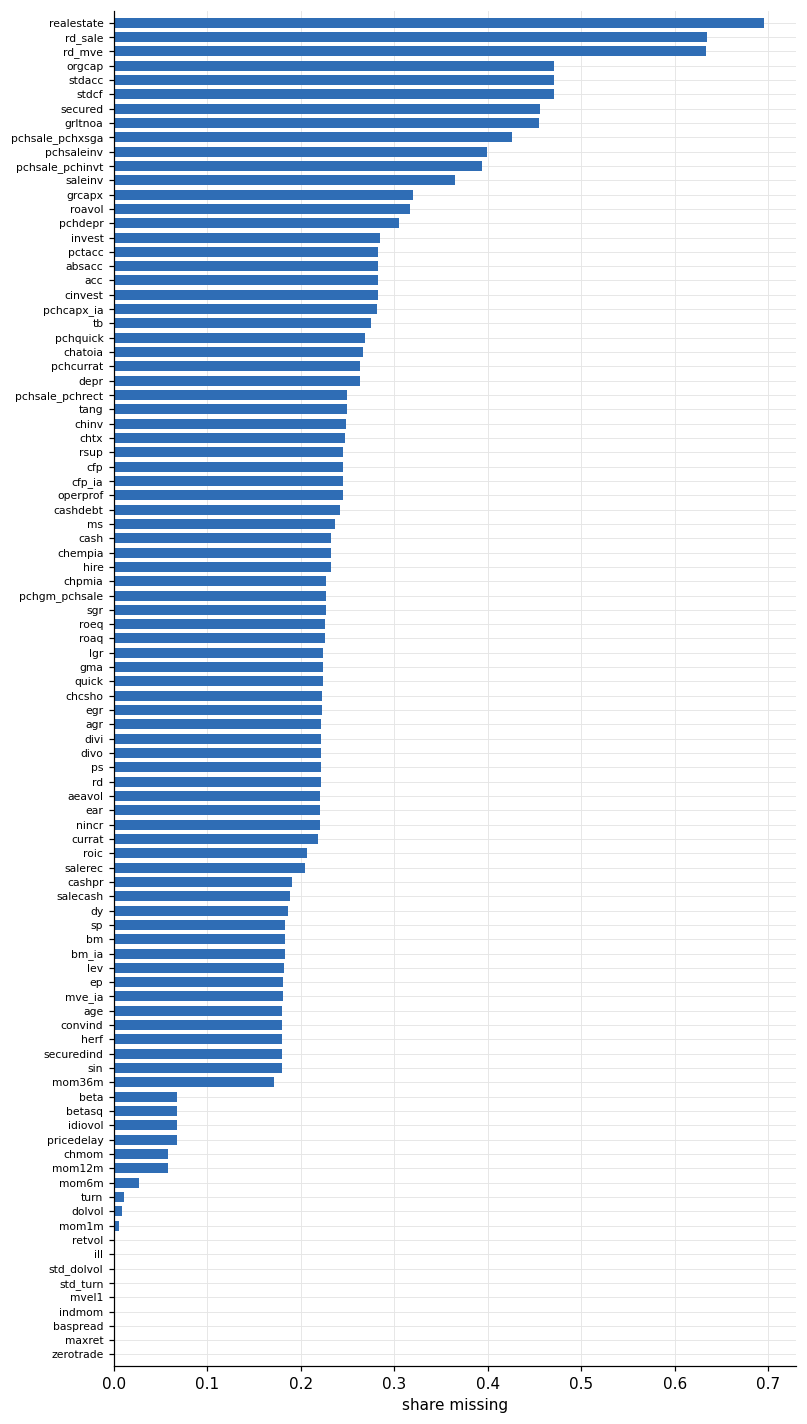

In [5]:
miss = (df.select([pl.col(c).is_null().mean().alias(c) for c in chars])
          .transpose(include_header=True, header_name="char", column_names=["missing"])
          .sort("missing", descending=True))
fig, ax = plt.subplots(figsize=(8, 16))
ax.barh(miss["char"][::-1], miss["missing"][::-1], color=BLUE, height=0.7)
ax.set_xlabel("share missing"); ax.tick_params(axis="y", labelsize=7); ax.margins(y=0.005); plt.show()

## Missing share by year

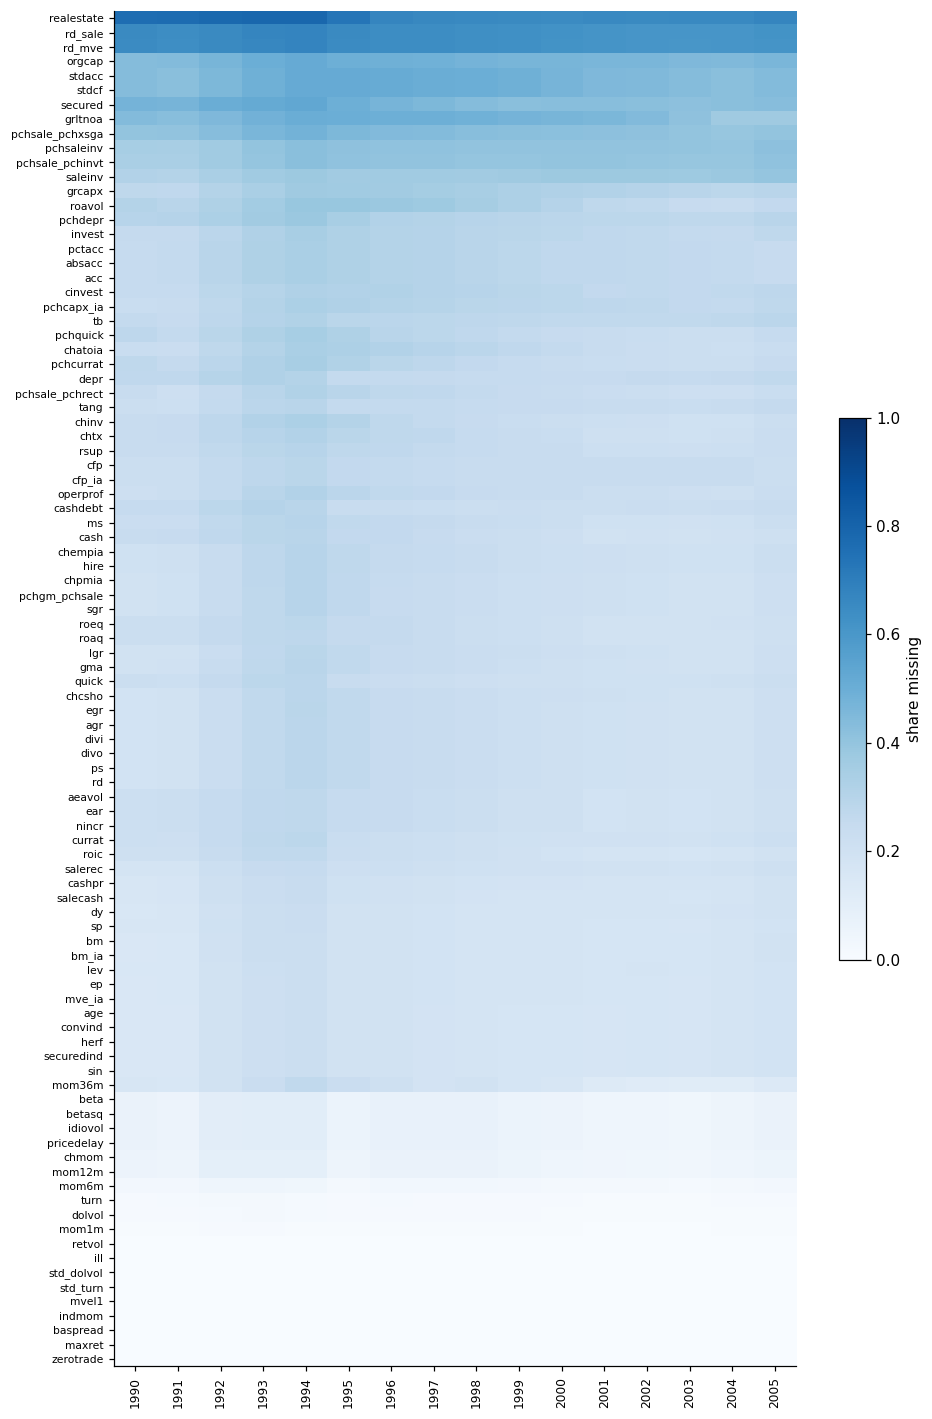

In [6]:
by_year = (df.with_columns((pl.col("DATE") // 10000).alias("year")).group_by("year")
             .agg([pl.col(c).is_null().mean() for c in chars]).sort("year"))
order = miss["char"].to_list()
fig, ax = plt.subplots(figsize=(10, 16))
im = ax.imshow(by_year.select(order).to_numpy().T, aspect="auto", cmap="Blues", vmin=0, vmax=1)
ax.set_yticks(range(len(order)), order, fontsize=7)
ax.set_xticks(range(by_year.height), by_year["year"], rotation=90, fontsize=8)
ax.grid(False); fig.colorbar(im, ax=ax, label="share missing", shrink=0.4); plt.show()

## Number of missing characteristics per firm-month

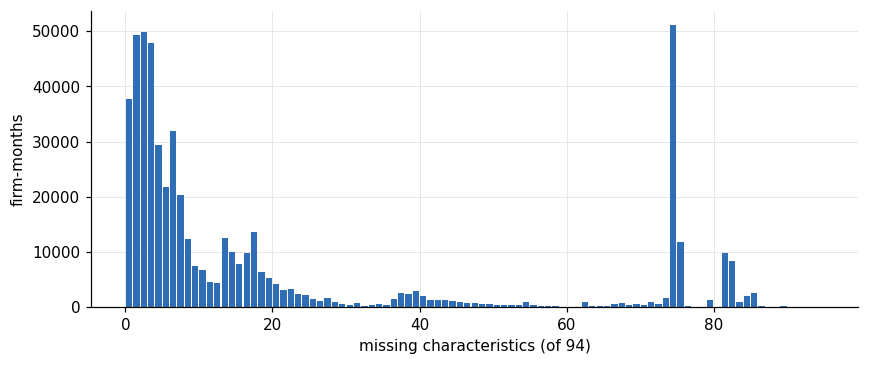

In [7]:
fig, ax = plt.subplots(figsize=(9, 3.5))
ax.hist(df["n_missing"], bins=range(0, len(chars) + 2), color=BLUE, rwidth=0.85)
ax.set_xlabel(f"missing characteristics (of {len(chars)})"); ax.set_ylabel("firm-months"); plt.show()

## Share of rows removed by a row-level missingness cutoff

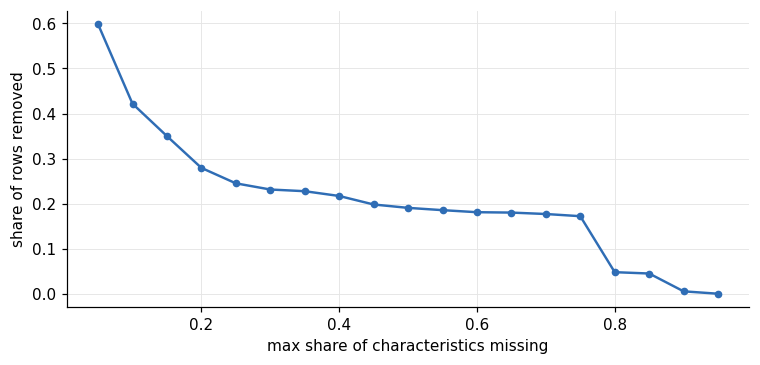

In [8]:
cutoffs = np.linspace(0.05, 0.95, 19)
removed = [(df["n_missing"] > c * len(chars)).mean() for c in cutoffs]
fig, ax = plt.subplots(figsize=(8, 3.5))
ax.plot(cutoffs, removed, marker="o", ms=4, color=BLUE, lw=1.6)
ax.set_xlabel("max share of characteristics missing"); ax.set_ylabel("share of rows removed"); plt.show()

## Profile of firm-months with more than half the characteristics missing

In [9]:
first_seen = lf.group_by("permno").agg(pl.col("DATE").min().alias("first_date")).collect()
prof = df.join(first_seen, on="permno").with_columns(
    (pl.col("n_missing") > len(chars) / 2).alias("over_half_missing"),
    ((pl.col("DATE") // 10000 - pl.col("first_date") // 10000) * 12
     + (pl.col("DATE") // 100 % 100 - pl.col("first_date") // 100 % 100)).alias("months_in_panel"),
)
prof.group_by("over_half_missing").agg(
    pl.len().alias("rows"),
    pl.col("months_in_panel").median().alias("median_months_in_panel"),
    pl.col("mvel1").median().alias("median_mvel1"),
    (pl.col("first_date") == pl.col("first_date").min()).mean().alias("share_in_panel_from_start"),
    pl.col("ret").mean().alias("mean_ret"), pl.col("ret").std().alias("std_ret"),
).sort("over_half_missing")

over_half_missing,rows,median_months_in_panel,median_mvel1,share_in_panel_from_start,mean_ret,std_ret
bool,u32,f64,f64,f64,f64,f64
false,432012,71.0000,676106.4387,0.6457,0.0132,0.1265
true,100716,29.0000,220966.4377,0.2865,0.0091,0.0985


## Characteristics present in firm-months with more than half missing

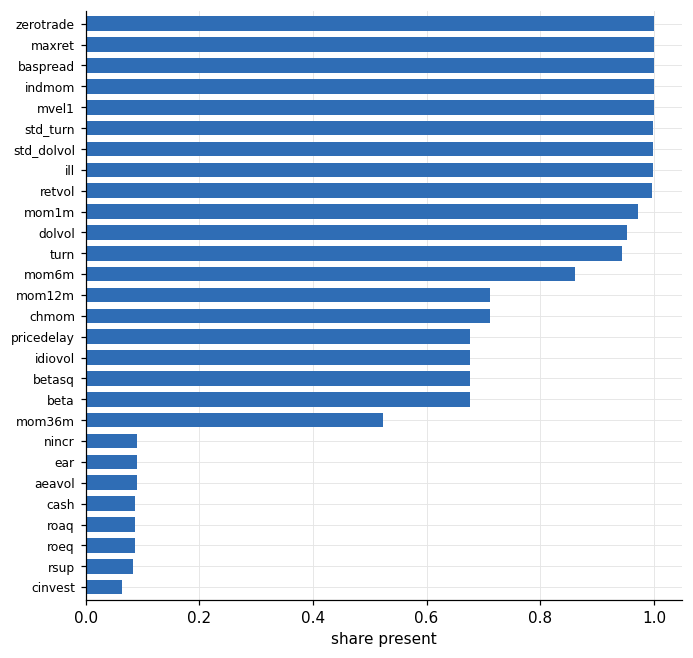

In [10]:
hi = df.filter(pl.col("n_missing") > len(chars) / 2)
present = (hi.select([pl.col(c).is_not_null().mean().alias(c) for c in chars])
             .transpose(include_header=True, header_name="char", column_names=["present"])
             .filter(pl.col("present") > 0.05).sort("present"))
fig, ax = plt.subplots(figsize=(7, 0.22 * present.height + 0.8))
ax.barh(present["char"], present["present"], color=BLUE, height=0.7)
ax.set_xlabel("share present"); ax.tick_params(axis="y", labelsize=8); ax.margins(y=0.01); plt.show()

## Missing share per characteristic before and after removing rows with more than half missing

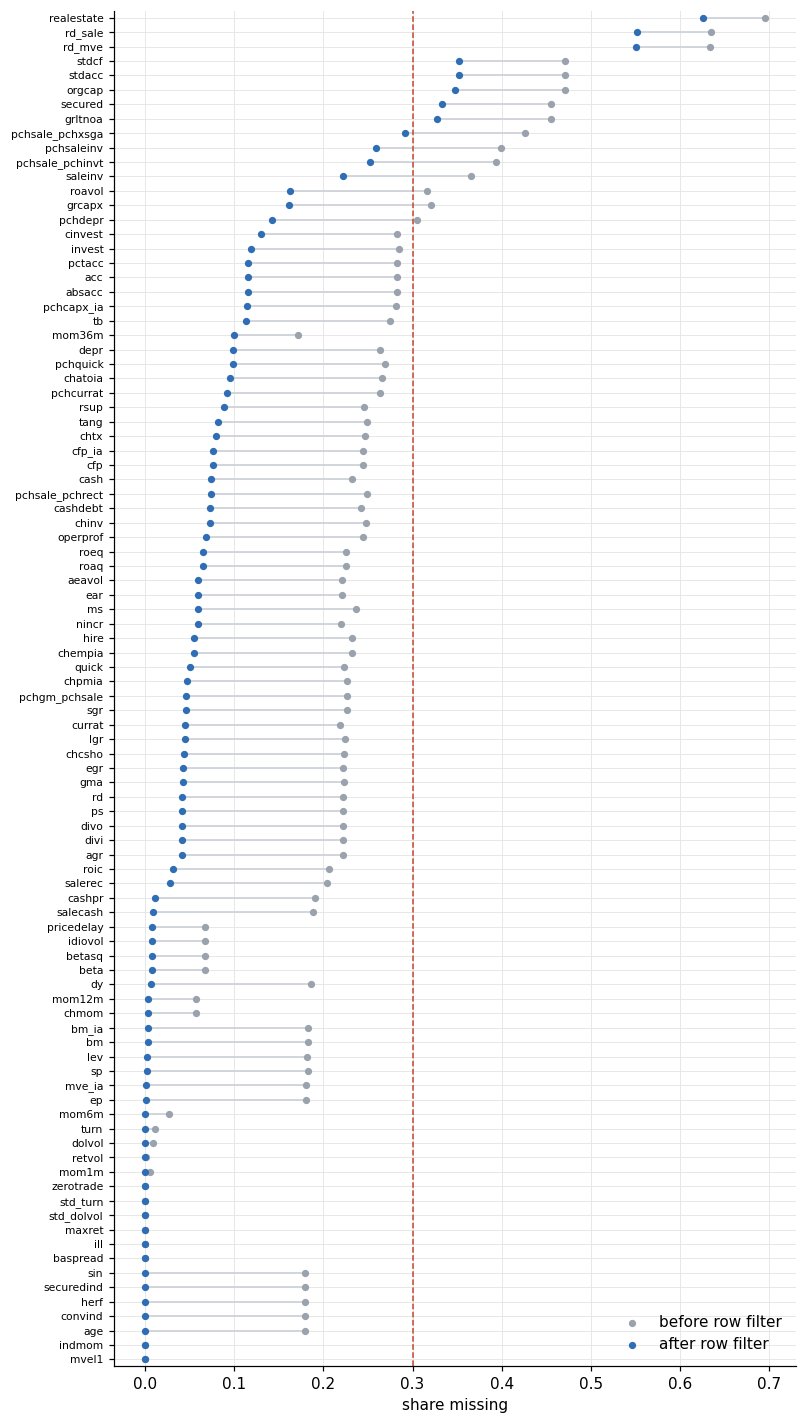

In [11]:
kept = df.filter(pl.col("n_missing") <= len(chars) / 2)
both = miss.join(kept.select([pl.col(c).is_null().mean().alias(c) for c in chars])
                     .transpose(include_header=True, header_name="char", column_names=["after"]), on="char")
both = both.sort("after")
fig, ax = plt.subplots(figsize=(8, 16))
y = np.arange(both.height)
ax.hlines(y, both["after"], both["missing"], color="#d0d4d9", lw=1.2)
ax.scatter(both["missing"], y, s=14, color=GREY, label="before row filter", zorder=3)
ax.scatter(both["after"], y, s=14, color=BLUE, label="after row filter", zorder=3)
ax.axvline(0.3, color="#c4462f", lw=1, ls="--")
ax.set_yticks(y, both["char"], fontsize=7); ax.margins(y=0.005)
ax.set_xlabel("share missing"); ax.legend(frameon=False, loc="lower right"); plt.show()

## Size cutoff: computed on all firm-months vs only firm-months with a return

In [12]:
base = lf.filter(pl.col("DATE") <= IS_END_DATE)
cut_all = base.group_by("DATE").agg(pl.col("mvel1").quantile(MIN_SIZE_QUANTILE).alias("cut_all"))
cut_ret = (base.join(ret_keys, on=["permno", "ym"], how="semi").group_by("DATE")
               .agg(pl.col("mvel1").quantile(MIN_SIZE_QUANTILE).alias("cut_with_return")))
order_a = size_zerotrade_filter(base).join(ret_keys, on=["permno", "ym"], how="semi").select(pl.len()).collect().item()
order_b = size_zerotrade_filter(base.join(ret_keys, on=["permno", "ym"], how="semi")).select(pl.len()).collect().item()
print("rows: filter then join returns =", order_a, "| join returns then filter =", order_b)
cut_all.join(cut_ret, on="DATE").collect().select(pl.col("cut_all", "cut_with_return").median())

rows: filter then join returns = 607822 | join returns then filter = 532728


cut_all,cut_with_return
f64,f64
23563.6801,70703.0000
